# Recording Inventory and Train/Validation Balance

This notebook reads recording filenames and, for mined crops, their `.mining.json` provenance. It does not read IMU signals or modify files. The validation-source exposure section additionally reads only `timestamp_ms` from hash-verified original source CSVs to total their actual duration.

Expected names are `imu_<person>_<gesture>_<YYYYMMDD>_<HHMMSS>.csv` and `imuStrict_<person>_<gesture>_<YYYYMMDD>_<HHMMSS>.csv`. The gesture is everything after the participant name and before the timestamp. For example, `imu_Miguel_knock_twice_left_20260929_142641.csv` is attributed to participant `Miguel` and gesture `knock_twice_left`.

Mined `negative_mining` **and** `normal_usage` crops are both training/report `hard_negative` recordings. Their original source action, filename, hash, and bounds remain audit columns. `imu_<collector>_switch_doubletap_<timestamp>.csv` remains a separate standard negative gesture: it counts as one full recording, not as a mined crop.


In [1]:
from __future__ import annotations

import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# This works when the notebook is started from the repository root or notebooks_analysis/.
working_dir = Path.cwd().resolve()
REPO_ROOT = next((path for path in (working_dir, *working_dir.parents)
                  if (path / 'tap_recognition').is_dir()), None)
assert REPO_ROOT is not None, 'Run this notebook inside the TapRecognition repository.'

# Change this to Path('/data') or another directory when auditing a different dataset.
DATA_DIR = REPO_ROOT / 'data_15_10_26'
MINING_SOURCE_DIR = REPO_ROOT / 'hard_negative_mining/source_recordings'

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
print(f'Repository: {REPO_ROOT}')
print(f'Data directory: {DATA_DIR}')
print(f'Mining source directory: {MINING_SOURCE_DIR}')


Repository: /home/miguel/TapRecognition
Data directory: /home/miguel/TapRecognition/data_15_10_26
Mining source directory: /home/miguel/TapRecognition/hard_negative_mining/source_recordings


## Discover and parse recordings

A file under `train_data` is classified as `train`; one under `valid_data` or `validation_data` is classified as `validation`. Files elsewhere remain `unassigned`, which makes it easy to audit an unsplit `/data` directory.

A crop suffix is valid only for `negative_mining`, hard-negative aliases, or `normal_usage`. All valid crops are reported as `hard_negative`, while `source_action`, `crop_source_file`, and `crop_source_sha256` retain their origin. Full `negative_mining` recordings are also reported as `hard_negative`; full `normal_usage` recordings remain `normal_usage`.


In [2]:
FILENAME_PATTERN = re.compile(
    r'^(?P<collection>imu(?:Strict)?)_(?P<person>[^_]+)_'
    r'(?P<gesture>.+)_(?P<timestamp>\d{8}_\d{6})'
    r'(?:(?P<hard_negative_crop>__crop_f(?P<crop_start_frame>\d+)_f(?P<crop_end_frame>\d+)))?\.csv$',
    re.IGNORECASE,
)
SPLIT_BY_DIRECTORY = {
    'train_data': 'train',
    'valid_data': 'validation',
    'validation_data': 'validation',
}
HARD_NEGATIVE_ACTIONS = {'negative_mining', 'hard_negative', 'hard_negatives', 'hard-negatives'}
CROP_SOURCE_ACTIONS = HARD_NEGATIVE_ACTIONS | {'normal_usage'}
switch_doubletap_example = FILENAME_PATTERN.fullmatch('imu_Miguel_switch_doubletap_20261012_170000.csv')
assert switch_doubletap_example is not None
assert switch_doubletap_example['gesture'] == 'switch_doubletap'
assert switch_doubletap_example['collection'] == 'imu' and switch_doubletap_example['hard_negative_crop'] is None


def split_from_path(path: Path) -> str:
    for part in path.parts:
        split = SPLIT_BY_DIRECTORY.get(part.lower())
        if split is not None:
            return split
    return 'unassigned'


def crop_provenance(path: Path) -> tuple[str, str, str]:
    """Return source filename, SHA-256, and original collection action for a crop."""
    metadata_path = path.with_suffix('.mining.json')
    if not metadata_path.is_file():
        raise FileNotFoundError(f'{metadata_path}: mined crops require provenance')
    metadata = json.loads(metadata_path.read_text())
    selection = metadata.get('selection', {})
    source_file = selection.get('file')
    source_sha256 = metadata.get('source_sha256')
    if (not isinstance(source_file, str) or Path(source_file).name != source_file
            or not isinstance(source_sha256, str) or len(source_sha256) != 64):
        raise ValueError(f'{metadata_path}: invalid source filename/hash provenance')
    if selection.get('source_sha256', source_sha256) != source_sha256:
        raise ValueError(f'{metadata_path}: inconsistent source SHA-256 provenance')
    source_match = FILENAME_PATTERN.fullmatch(source_file)
    if source_match is None:
        raise ValueError(f'{metadata_path}: source filename is not an expected IMU recording')
    source_action = source_match['gesture'].lower()
    if source_action not in CROP_SOURCE_ACTIONS:
        raise ValueError(f'{metadata_path}: unsupported crop source action {source_action!r}')
    return source_file, source_sha256, source_action


csv_paths = sorted(
    path for path in DATA_DIR.rglob('*.csv')
    if (not path.name.endswith('.labels.csv')
        and path.name.lower().startswith(('imu_', 'imustrict_')))
)
rows = []
unparsed = []
for path in csv_paths:
    match = FILENAME_PATTERN.fullmatch(path.name)
    relative_path = str(path.relative_to(DATA_DIR))
    if match is None:
        unparsed.append(relative_path)
        continue
    fields = match.groupdict()
    source_action = fields['gesture'].lower()
    has_crop_suffix = fields['hard_negative_crop'] is not None
    if has_crop_suffix and source_action not in CROP_SOURCE_ACTIONS:
        unparsed.append(relative_path)
        continue
    crop_start = int(fields['crop_start_frame']) if has_crop_suffix else pd.NA
    crop_end = int(fields['crop_end_frame']) if has_crop_suffix else pd.NA
    if has_crop_suffix and crop_start >= crop_end:
        unparsed.append(relative_path)
        continue
    crop_source_file = crop_source_sha256 = crop_source_action = pd.NA
    try:
        if has_crop_suffix:
            crop_source_file, crop_source_sha256, crop_source_action = crop_provenance(path)
    except (FileNotFoundError, ValueError) as error:
        unparsed.append(f'{relative_path}: {error}')
        continue
    is_hard_negative = source_action in HARD_NEGATIVE_ACTIONS or has_crop_suffix
    rows.append({
        'path': relative_path,
        'collection': fields['collection'],
        'person': fields['person'],
        'gesture': 'hard_negative' if is_hard_negative else source_action,
        'source_action': source_action,
        'crop_start_frame': crop_start,
        'crop_end_frame': crop_end,
        'crop_source_file': crop_source_file,
        'crop_source_sha256': crop_source_sha256,
        'crop_source_action': crop_source_action,
        'timestamp': pd.to_datetime(fields['timestamp'], format='%Y%m%d_%H%M%S'),
        'split': split_from_path(path),
    })

records = pd.DataFrame(rows, columns=['path', 'collection', 'person', 'gesture', 'source_action',
                                      'crop_start_frame', 'crop_end_frame', 'crop_source_file',
                                      'crop_source_sha256', 'crop_source_action', 'timestamp', 'split'])
if records.empty:
    raise RuntimeError(f'No recording filenames matching the expected format were found under {DATA_DIR}.')
records = records.sort_values(['split', 'person', 'gesture', 'timestamp']).reset_index(drop=True)

print(f'CSV files found: {len(csv_paths)}')
print(f'Recordings parsed: {len(records)}')
print(f'Filename/provenance record(s) not parsed: {len(unparsed)}')
display(records.head(10))
if unparsed:
    display(pd.DataFrame({'unparsed_csv': unparsed}))


CSV files found: 967
Recordings parsed: 967
Filename/provenance record(s) not parsed: 0


,path,collection,person,gesture,source_action,crop_start_frame,crop_end_frame,crop_source_file,crop_source_sha256,crop_source_action,timestamp,split
0,train_data/imu_Miguel_adjust_grip_20260921_172...,imu,Miguel,adjust_grip,adjust_grip,<NA>,<NA>,<NA>,<NA>,<NA>,2026-09-21 17:27:17,train
1,train_data/imu_Miguel_adjust_grip_20260923_175...,imu,Miguel,adjust_grip,adjust_grip,<NA>,<NA>,<NA>,<NA>,<NA>,2026-09-23 17:58:13,train
2,train_data/imu_Miguel_adjust_grip_20260929_141...,imu,Miguel,adjust_grip,adjust_grip,<NA>,<NA>,<NA>,<NA>,<NA>,2026-09-29 14:19:22,train
3,train_data/imu_Miguel_adjust_grip_20260929_142...,imu,Miguel,adjust_grip,adjust_grip,<NA>,<NA>,<NA>,<NA>,<NA>,2026-09-29 14:20:34,train
4,train_data/imu_Miguel_arbitrary_20260921_17241...,imu,Miguel,arbitrary,arbitrary,<NA>,<NA>,<NA>,<NA>,<NA>,2026-09-21 17:24:16,train
5,train_data/imu_Miguel_arbitrary_20260924_09360...,imu,Miguel,arbitrary,arbitrary,<NA>,<NA>,<NA>,<NA>,<NA>,2026-09-24 09:36:02,train
6,train_data/imu_Miguel_negative_mining_20261009...,imu,Miguel,hard_negative,negative_mining,444,744,imu_Miguel_negative_mining_20261009_164938.csv,ed7ea66b25a72b7aeaf779943fc6ced6526fda28683ec1...,negative_mining,2026-10-09 16:49:38,train
7,train_data/imu_Miguel_negative_mining_20261009...,imu,Miguel,hard_negative,negative_mining,1390,1690,imu_Miguel_negative_mining_20261009_164938.csv,ed7ea66b25a72b7aeaf779943fc6ced6526fda28683ec1...,negative_mining,2026-10-09 16:49:38,train
8,train_data/imu_Miguel_negative_mining_20261009...,imu,Miguel,hard_negative,negative_mining,1910,2210,imu_Miguel_negative_mining_20261009_164938.csv,ed7ea66b25a72b7aeaf779943fc6ced6526fda28683ec1...,negative_mining,2026-10-09 16:49:38,train
9,train_data/imu_Miguel_negative_mining_20261009...,imu,Miguel,hard_negative,negative_mining,2078,2378,imu_Miguel_negative_mining_20261009_164938.csv,ed7ea66b25a72b7aeaf779943fc6ced6526fda28683ec1...,negative_mining,2026-10-09 16:49:38,train


## Inventory by gesture and participant

,recordings,recording equivalents for gesture share,gestures,people,strict recordings,unassigned recordings
0,967,238.35,10,7,65,0


Recordings per gesture (hard_negative uses 1/20 per crop for its share)


,recordings,recording_equivalents,people,first_recording,last_recording,share_of_recording_equivalents_pct
gesture,,,,,,
knock_twice_right,54,54.00,6,2026-09-04 09:51:27,2026-10-14 19:18:34,22.7
knock_twice_left,47,47.00,6,2026-09-04 09:50:15,2026-10-14 19:19:41,19.7
hard_negative,767,38.35,1,2026-10-09 16:49:38,2026-10-15 11:00:13,16.1
knock_once,28,28.00,3,2026-09-21 17:21:28,2026-10-13 17:31:47,11.7
switch_hand,22,22.00,2,2026-09-09 09:28:38,2026-10-13 17:42:38,9.2
shake_phone,21,21.00,3,2026-09-04 10:28:26,2026-10-06 09:53:51,8.8
pick_place,10,10.00,2,2026-09-09 09:13:35,2026-10-12 17:30:59,4.2
switch_doubletap,10,10.00,1,2026-10-12 17:02:39,2026-10-13 17:41:25,4.2
adjust_grip,5,5.00,1,2026-09-21 17:27:17,2026-09-29 14:20:34,2.1


Recording count by participant


,recordings,gestures,first_recording,last_recording
person,,,,
Miguel,948,10,2026-09-21 17:16:41,2026-10-15 11:00:13
ZR,7,4,2026-09-04 10:28:26,2026-10-09 16:41:59
OLV,4,4,2026-09-23 17:43:50,2026-09-23 17:49:32
JYH,2,2,2026-09-16 14:28:14,2026-09-16 14:29:27
YYQ,2,2,2026-09-04 09:57:40,2026-09-04 09:58:56
Ym,2,2,2026-09-04 11:09:25,2026-09-04 11:10:43
yzj,2,2,2026-09-04 09:50:15,2026-09-04 09:51:27


Recording count by participant and gesture


gesture,adjust_grip,arbitrary,hard_negative,knock_once,knock_twice_left,knock_twice_right,pick_place,shake_phone,switch_doubletap,switch_hand
person,,,,,,,,,,
JYH,0,0,0,0,1,1,0,0,0,0
Miguel,5,3,767,25,42,49,9,17,10,21
OLV,0,0,0,1,1,1,0,1,0,0
YYQ,0,0,0,0,1,1,0,0,0,0
Ym,0,0,0,0,1,1,0,0,0,0
ZR,0,0,0,2,0,0,1,3,0,1
yzj,0,0,0,0,1,1,0,0,0,0


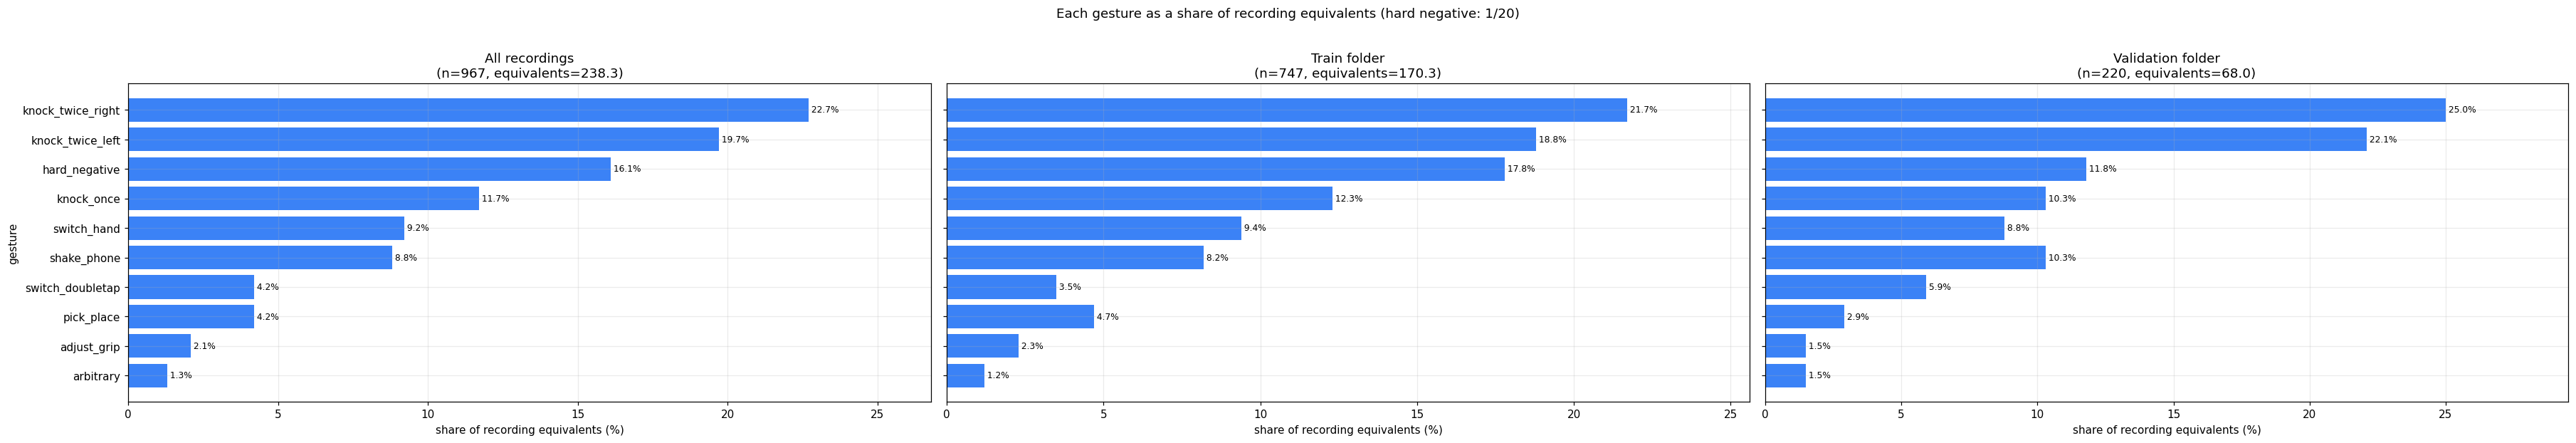

In [3]:
# Mined crops are short slices of a recording, not independent collection sessions.
# Keep their raw count for audit, but make 20 crops equal one recording when
# calculating the gesture-share percentage below. This applies equally to
# negative_mining and normal_usage source crops, both recorded as hard_negative.
HARD_NEGATIVE_CROPS_PER_RECORDING = 20
records['gesture_share_weight'] = np.where(
    records.gesture.eq('hard_negative'), 1 / HARD_NEGATIVE_CROPS_PER_RECORDING, 1.0
)


def gesture_equivalent_inventory(frame: pd.DataFrame) -> pd.DataFrame:
    if frame.empty:
        return pd.DataFrame(columns=['recordings', 'recording_equivalents', 'people',
                                     'first_recording', 'last_recording',
                                     'share_of_recording_equivalents_pct'])
    result = (
        frame.groupby('gesture')
        .agg(recordings=('path', 'size'), recording_equivalents=('gesture_share_weight', 'sum'),
             people=('person', 'nunique'), first_recording=('timestamp', 'min'),
             last_recording=('timestamp', 'max'))
        .sort_values(['recording_equivalents', 'gesture'], ascending=[False, True])
    )
    result['share_of_recording_equivalents_pct'] = (
        100 * result['recording_equivalents'] / frame['gesture_share_weight'].sum()
    ).round(1)
    return result


overview = pd.DataFrame({
    'recordings': [len(records)],
    'recording equivalents for gesture share': [records.gesture_share_weight.sum()],
    'gestures': [records['gesture'].nunique()],
    'people': [records['person'].nunique()],
    'strict recordings': [(records['collection'].str.lower() == 'imustrict').sum()],
    'unassigned recordings': [(records['split'] == 'unassigned').sum()],
})
display(overview)

gesture_inventory = gesture_equivalent_inventory(records)
person_inventory = (
    records.groupby('person')
    .agg(recordings=('path', 'size'), gestures=('gesture', 'nunique'),
         first_recording=('timestamp', 'min'), last_recording=('timestamp', 'max'))
    .sort_values(['recordings', 'person'], ascending=[False, True])
)

print(f'Recordings per gesture (hard_negative uses 1/{HARD_NEGATIVE_CROPS_PER_RECORDING} per crop for its share)')
display(gesture_inventory)

split_frames = {
    'All recordings': records,
    'Train folder': records[records['split'] == 'train'],
    'Validation folder': records[records['split'] == 'validation'],
}
gesture_order = gesture_inventory.index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(max(18, len(gesture_order) * 3.3),
                                        max(3.5, len(gesture_order) * .55)), sharey=True)
for axis, (title, frame) in zip(axes, split_frames.items()):
    inventory = gesture_equivalent_inventory(frame)
    shares = inventory['share_of_recording_equivalents_pct'].reindex(gesture_order, fill_value=0).sort_values()
    bars = axis.barh(shares.index, shares.values, color='#3B82F6')
    axis.set_title(f'{title}\n(n={len(frame)}, equivalents={frame.gesture_share_weight.sum():.1f})')
    axis.set_xlabel('share of recording equivalents (%)')
    axis.set_xlim(0, max(1, shares.max() * 1.18))
    for bar in bars:
        axis.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
                  f' {bar.get_width():.1f}%', va='center', fontsize=8)
axes[0].set_ylabel('gesture')
fig.suptitle(f'Each gesture as a share of recording equivalents (hard negative: 1/{HARD_NEGATIVE_CROPS_PER_RECORDING})', y=1.02)
fig.tight_layout()

print('Recording count by participant')
display(person_inventory)
print('Recording count by participant and gesture')
display(pd.crosstab(records['person'], records['gesture']))


## Train/validation balance

The validation percentage is compared with the overall validation percentage among assigned recordings. A large positive or negative `delta_vs_overall_pp` means that gesture or participant is over-represented in validation or training. `unassigned` recordings are shown but excluded from that percentage.

In [4]:
SPLIT_ORDER = ['train', 'validation', 'unassigned']
assigned = records[records['split'].isin(['train', 'validation'])]
overall_validation_pct = (
    100 * (assigned['split'] == 'validation').mean() if len(assigned) else np.nan
)
print(f'Overall validation share among assigned recordings: {overall_validation_pct:.1f}%')

def balance_table(column: str) -> pd.DataFrame:
    table = pd.crosstab(records[column], records['split']).reindex(columns=SPLIT_ORDER, fill_value=0)
    assigned_total = table['train'] + table['validation']
    table['total'] = assigned_total + table['unassigned']
    table['validation_pct'] = (100 * table['validation'] / assigned_total.replace(0, np.nan)).round(1)
    table['delta_vs_overall_pp'] = (table['validation_pct'] - overall_validation_pct).round(1)
    return table.sort_values('total', ascending=False, kind='stable')

gesture_balance = balance_table('gesture')
person_balance = balance_table('person')
print('Balance by gesture')
display(gesture_balance)
print('Balance by participant')
display(person_balance)

Overall validation share among assigned recordings: 22.8%
Balance by gesture


split,train,validation,unassigned,total,validation_pct,delta_vs_overall_pp
gesture,,,,,,
hard_negative,607,160,0,767,20.9,-1.9
knock_twice_right,37,17,0,54,31.5,8.7
knock_twice_left,32,15,0,47,31.9,9.1
knock_once,21,7,0,28,25.0,2.2
switch_hand,16,6,0,22,27.3,4.5
shake_phone,14,7,0,21,33.3,10.5
pick_place,8,2,0,10,20.0,-2.8
switch_doubletap,6,4,0,10,40.0,17.2
adjust_grip,4,1,0,5,20.0,-2.8


Balance by participant


split,train,validation,unassigned,total,validation_pct,delta_vs_overall_pp
person,,,,,,
Miguel,737,211,0,948,22.3,-0.5
ZR,0,7,0,7,100.0,77.2
OLV,4,0,0,4,0.0,-22.8
JYH,0,2,0,2,100.0,77.2
YYQ,2,0,0,2,0.0,-22.8
Ym,2,0,0,2,0.0,-22.8
yzj,2,0,0,2,0.0,-22.8


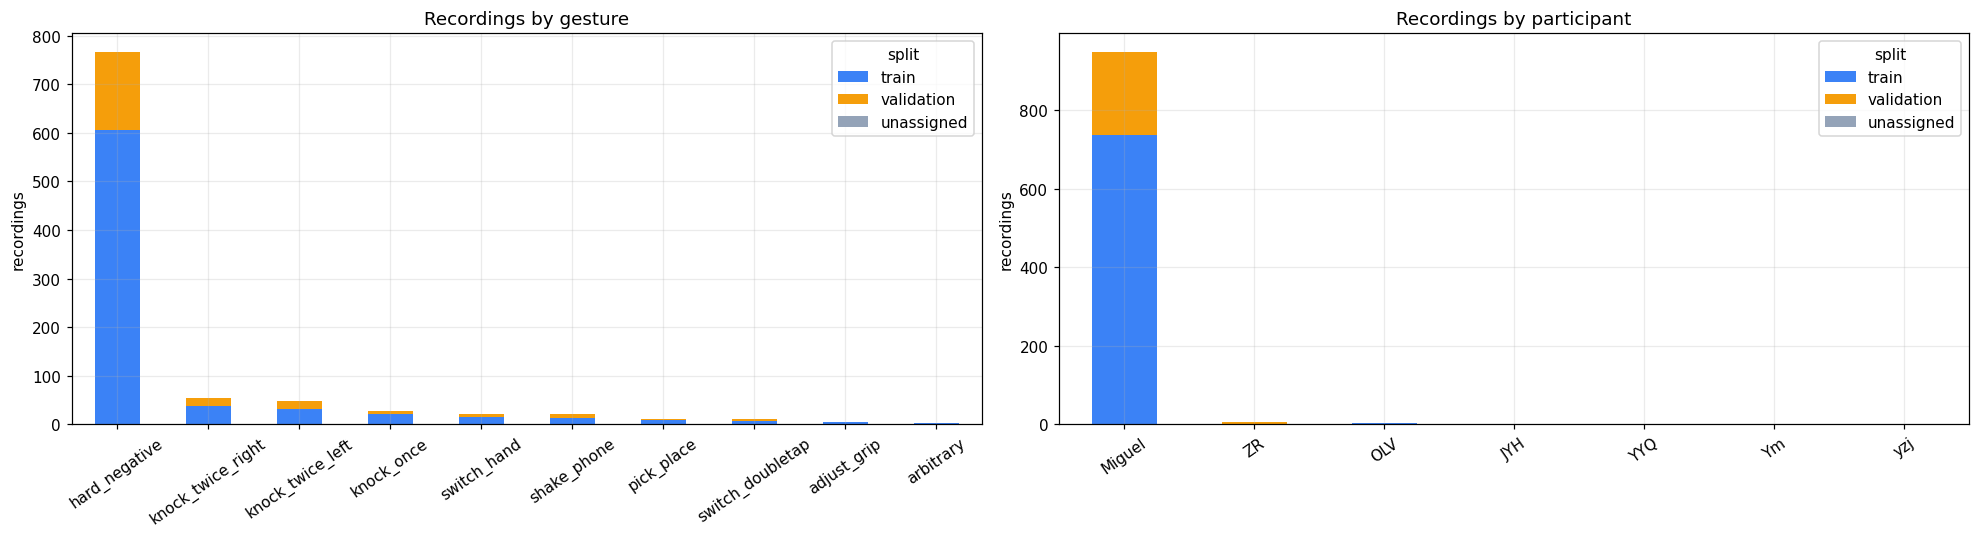

In [5]:
def plot_split_counts(table: pd.DataFrame, title: str, ax: plt.Axes) -> None:
    table[SPLIT_ORDER].plot(
        kind='bar', stacked=True, ax=ax,
        color={'train': '#3B82F6', 'validation': '#F59E0B', 'unassigned': '#94A3B8'},
    )
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('recordings')
    ax.tick_params(axis='x', rotation=35)
    ax.legend(title='split')

fig, axes = plt.subplots(1, 2, figsize=(max(14, len(gesture_balance) * 1.25 + len(person_balance) * 0.8), 5))
plot_split_counts(gesture_balance, 'Recordings by gesture', axes[0])
plot_split_counts(person_balance, 'Recordings by participant', axes[1])
fig.tight_layout()

## Original-source exposure behind validation crops

Validation mined crops are failure-enriched slices, not their full original recordings. This table deduplicates their hash-verified originals and totals the actual full-source duration separately for `normal_usage` and `negative_mining`. It is an audit of validation source coverage, not a replayed false-positive rate and not a duration to add to the crop input duration.


In [6]:
# Jupyter may start with a sys.path that does not include the repository root.
import sys
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tap_recognition.recording import estimate_sample_rate_hz

validation_crops = records[(records['split'] == 'validation') & records['crop_source_sha256'].notna()].copy()
if validation_crops.empty:
    print('No mined crops in the validation folder.')
    validation_crop_source_inventory = pd.DataFrame()
    validation_crop_source_summary = pd.DataFrame()
else:
    source_rows = []
    for source_hash, crops in validation_crops.groupby('crop_source_sha256', sort=True):
        source_file = crops['crop_source_file'].iloc[0]
        source_action = crops['crop_source_action'].iloc[0]
        assert crops['crop_source_file'].eq(source_file).all()
        assert crops['crop_source_action'].eq(source_action).all()
        source_path = MINING_SOURCE_DIR / source_file
        if not source_path.is_file():
            raise FileNotFoundError(f'{source_path}: validation crop original is unavailable')
        actual_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
        if actual_hash != source_hash:
            raise ValueError(f'{source_path}: hash differs from crop provenance')
        timestamps = pd.read_csv(source_path, usecols=['timestamp_ms']).timestamp_ms.to_numpy(dtype=float)
        if len(timestamps) < 2 or not np.isfinite(timestamps).all():
            raise ValueError(f'{source_path}: original needs at least two finite timestamps')
        sample_rate_hz = estimate_sample_rate_hz(timestamps)
        if (not np.all(np.diff(timestamps) > 0)
                or not np.allclose(np.diff(timestamps), 1000 / sample_rate_hz, atol=.01, rtol=0)):
            raise ValueError(f'{source_path}: original timestamps must be uniformly sampled')
        source_rows.append(dict(
            source_action=source_action,
            source_file=source_file,
            source_sha256=source_hash,
            source_frames=len(timestamps),
            sample_rate_hz=sample_rate_hz,
            original_minutes=len(timestamps) / sample_rate_hz / 60,
            validation_crops=len(crops),
        ))
    validation_crop_source_inventory = pd.DataFrame(source_rows).sort_values(
        ['source_action', 'source_file']).reset_index(drop=True)
    validation_crop_source_summary = (
        validation_crop_source_inventory.groupby('source_action', dropna=False)
        .agg(original_recordings=('source_file', 'size'), validation_crops=('validation_crops', 'sum'),
             original_minutes=('original_minutes', 'sum'))
        .sort_values('source_action')
    )
    validation_crop_source_summary['original_hours'] = (
        validation_crop_source_summary['original_minutes'] / 60
    ).round(3)
    validation_crop_source_summary['original_minutes'] = (
        validation_crop_source_summary['original_minutes'].round(3)
    )
    print('Validation crops grouped by hash-verified original source:')
    display(validation_crop_source_summary)
    display(validation_crop_source_inventory)


FileNotFoundError: /home/miguel/TapRecognition/hard_negative_mining/source_recordings/imu_Miguel_normal_usage_20261014_131245.csv: validation crop original is unavailable

## Participant-by-gesture coverage

This table shows the detailed split counts. The heatmap shows the percentage of assigned recordings in validation for every participant/gesture combination; `-` means that combination has no assigned recording.

split,person,gesture,train,validation,unassigned,total,validation_pct
4,Miguel,hard_negative,465,113,0,578,19.6
7,Miguel,knock_twice_right,33,15,0,48,31.2
6,Miguel,knock_twice_left,28,13,0,41,31.7
5,Miguel,knock_once,20,5,0,25,20.0
11,Miguel,switch_hand,16,5,0,21,23.8
9,Miguel,shake_phone,13,4,0,17,23.5
10,Miguel,switch_doubletap,6,4,0,10,40.0
8,Miguel,pick_place,8,1,0,9,11.1
2,Miguel,adjust_grip,4,1,0,5,20.0
3,Miguel,arbitrary,2,1,0,3,33.3


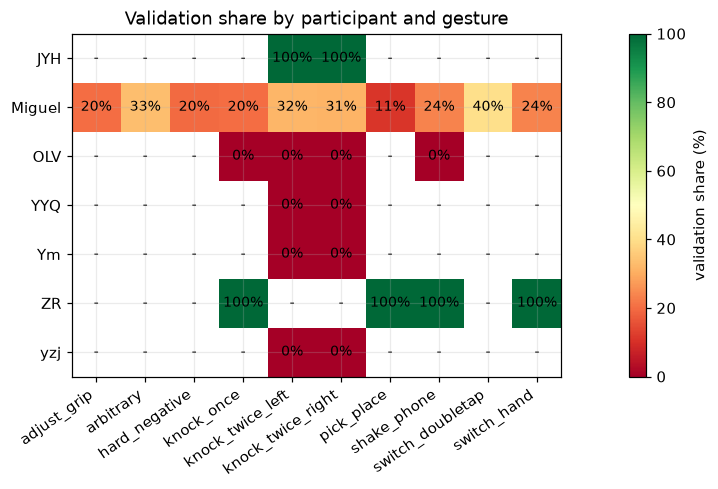

In [ ]:
pair_counts = pd.crosstab([records['person'], records['gesture']], records['split'])
pair_counts = pair_counts.reindex(columns=SPLIT_ORDER, fill_value=0)
pair_counts['total'] = pair_counts.sum(axis=1)
pair_counts['validation_pct'] = (
    100 * pair_counts['validation'] / (pair_counts['train'] + pair_counts['validation']).replace(0, np.nan)
).round(1)
display(pair_counts.reset_index().sort_values(['total', 'person', 'gesture'], ascending=[False, True, True]))

train_matrix = pd.crosstab(records['person'], records['gesture'],
                           values=(records['split'] == 'train'), aggfunc='sum').fillna(0)
validation_matrix = pd.crosstab(records['person'], records['gesture'],
                                values=(records['split'] == 'validation'), aggfunc='sum').fillna(0)
validation_matrix = validation_matrix.reindex(index=train_matrix.index, columns=train_matrix.columns, fill_value=0)
validation_share = 100 * validation_matrix / (train_matrix + validation_matrix).replace(0, np.nan)

fig, ax = plt.subplots(figsize=(max(8, len(validation_share.columns) * 1.25),
                               max(3, len(validation_share.index) * 0.65)))
image = ax.imshow(validation_share.to_numpy(dtype=float), vmin=0, vmax=100, cmap='RdYlGn')
ax.set_xticks(range(len(validation_share.columns)), validation_share.columns, rotation=35, ha='right')
ax.set_yticks(range(len(validation_share.index)), validation_share.index)
ax.set_title('Validation share by participant and gesture')
for row_index, person in enumerate(validation_share.index):
    for column_index, gesture in enumerate(validation_share.columns):
        value = validation_share.loc[person, gesture]
        ax.text(column_index, row_index, '-' if pd.isna(value) else f'{value:.0f}%',
                ha='center', va='center', fontsize=9)
fig.colorbar(image, ax=ax, label='validation share (%)')
fig.tight_layout()